## Propósito del Cuaderno: Reconocimiento de Emociones con Wav2Vec2

Este cuaderno tiene como objetivo entrenar y evaluar un modelo de aprendizaje profundo para la tarea de **Reconocimiento de Emociones en el Habla (SER)**.

### Aspectos destacados:
1. **Dataset:** Utiliza el dataset **SUPERB (Tarea ER)**, basado en grabaciones de audio etiquetadas con emociones (Neutral, Feliz, Triste, Enojado).
2. **Arquitectura:** Emplea el modelo preentrenado **Wav2Vec2** de Facebook, ajustándolo (fine-tuning) para la clasificación de secuencias de audio.
3. **Técnicas implementadas:**
   - **Data Augmentation:** Inserción de ruido y cambios de volumen para mejorar la robustez.
   - **Manejo de Desbalanceo:** Cálculo de pesos de clase para la función de pérdida.
   - **Optimización:** Uso de un programador de tasa de aprendizaje (`ReduceLROnPlateau`) y parada temprana (`EarlyStopping`).
   - **Evaluación Exhaustiva:** Análisis mediante matrices de confusión y métricas detalladas (F1-Macro, Precisión, Recall) para entender el rendimiento por cada emoción.

In [1]:
!pip install transformers datasets torch soundfile evaluate scikit-learn seaborn

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset, concatenate_datasets, Audio
from transformers import (
    Wav2Vec2FeatureExtractor,
    Wav2Vec2ForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    set_seed
)
from sklearn.utils.class_weight import compute_class_weight
import evaluate
from sklearn.metrics import classification_report, confusion_matrix

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 1.9 MB/s eta 0:00:00


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"️  Usando dispositivo: {device}")

# Cargamos el dataset SUPERB (Emociones)
print("\nDescargando dataset SUPERB (Tarea ER)...")
dataset = load_dataset("s3prl/superb", "er")

print("\nEstructura original del dataset:")
print(dataset)

# Nombres de las clases
print(dataset['session1'].features['label'].names)
nombres_clases = ['Neutral', 'Feliz', 'Triste', 'Enojado']
print(f"\n  Clases: {nombres_clases}")

SEED = 123
set_seed(SEED)

️  Usando dispositivo: cuda

Descargando dataset SUPERB (Tarea ER)...


README.md:   0%|          | 0.00/59.2k [00:00<?, ?B/s]

er/session1-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  164MB            

er/session1-00000-of-00001.parquet: downloading bytes:           |  0.00B            

er/session2-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  151MB            

...

Generating session2 split:   0%|          | 0/1023 [00:00<?, ? examples/s]

Generating session3 split:   0%|          | 0/1151 [00:00<?, ? examples/s]

Generating session4 split:   0%|          | 0/1031 [00:00<?, ? examples/s]

Generating session5 split:   0%|          | 0/1241 [00:00<?, ? examples/s]


Estructura original del dataset:
DatasetDict({
    session1: Dataset({
        features: ['file', 'audio', 'label'],
        num_rows: 1085
    })
    session2: Dataset({
        features: ['file', 'audio', 'label'],
        num_rows: 1023
    })
    session3: Dataset({
        features: ['file', 'audio', 'label'],
        num_rows: 1151
    })
    session4: Dataset({
        features: ['file', 'audio', 'label'],
        num_rows: 1031
    })
    session5: Dataset({
        features: ['file', 'audio', 'label'],
        num_rows: 1241
    })
})
['neu', 'hap', 'ang', 'sad']

  Clases: ['Neutral', 'Feliz', 'Triste', 'Enojado']


In [3]:
# Sesiones 1-4 para entrenamiento, Sesión 5 para evaluación
print("\nDividiendo dataset en train/eval...")
train_dataset = concatenate_datasets([
    dataset["session1"],
    dataset["session2"],
    dataset["session3"],
    dataset["session4"]
])
eval_dataset = dataset["session5"]

print(f"Train: {len(train_dataset)} samples")
print(f"Eval: {len(eval_dataset)} samples")

# Sampling rate a 16kHz (requerido por Wav2Vec2)
print("\nEstandarizando sampling rate a 16kHz...")
train_dataset = train_dataset.cast_column("audio", Audio(sampling_rate=16000))
eval_dataset = eval_dataset.cast_column("audio", Audio(sampling_rate=16000))

print("\n" + "="*60)
print("ANÁLISIS DE DESBALANCEO DE CLASES")
print("="*60)

# Samples por clase en entrenamiento
train_labels = train_dataset['label']
unique, counts = np.unique(train_labels, return_counts=True)

print("\nDistribución en ENTRENAMIENTO:")
for label, count in zip(unique, counts):
    porcentaje = (count / len(train_labels)) * 100
    print(f"  {nombres_clases[label]:10s}: {count:4d} samples ({porcentaje:5.2f}%)")

print("\nEstadísticas de duración de audio (Train):")
durations = [len(x['array']) / 16000 for x in train_dataset['audio']]
print(f"  Duración mínima: {min(durations):.2f} segundos")
print(f"  Duración máxima: {max(durations):.2f} segundos")
print(f"  Duración promedio: {np.mean(durations):.2f} segundos")
print(f"  Duración mediana: {np.median(durations):.2f} segundos")


Dividiendo dataset en train/eval...
Train: 4290 samples
Eval: 1241 samples

Estandarizando sampling rate a 16kHz...

ANÁLISIS DE DESBALANCEO DE CLASES

Distribución en ENTRENAMIENTO:
  Neutral   : 1324 samples (30.86%)
  Feliz     : 1194 samples (27.83%)
  Triste    :  933 samples (21.75%)
  Enojado   :  839 samples (19.56%)

Estadísticas de duración de audio (Train):
  Duración mínima: 0.58 segundos
  Duración máxima: 29.13 segundos
  Duración promedio: 4.57 segundos
  Duración mediana: 3.63 segundos


In [4]:
max_duration = 10.0
min_duration = 1.0

# Filtración por duración
train_dataset = train_dataset.filter(
    lambda x: min_duration <= len(x['audio']['array']) / 16000 <= max_duration
)
eval_dataset = eval_dataset.filter(
    lambda x: min_duration <= len(x['audio']['array']) / 16000 <= max_duration
)

print(f"Train (filtrado entre {min_duration}-{max_duration}s): {len(train_dataset)} samples")
print(f"Eval (filtrado entre {min_duration}-{max_duration}s): {len(eval_dataset)} samples")

print("\n" + "="*60)
print("ANÁLISIS DE DESBALANCEO DE CLASES")
print("="*60)

# Samples por clase en entrenamiento
train_labels = train_dataset['label']
unique, counts = np.unique(train_labels, return_counts=True)

print("\nDistribución en ENTRENAMIENTO:")
for label, count in zip(unique, counts):
    porcentaje = (count / len(train_labels)) * 100
    print(f"  {nombres_clases[label]:10s}: {count:4d} samples ({porcentaje:5.2f}%)")

# Calculamos estadísticas de duración de audio
print("\nEstadísticas de duración de audio (Train):")
durations = [len(x['array']) / 16000 for x in train_dataset['audio']]
print(f"  Duración mínima: {min(durations):.2f} segundos")
print(f"  Duración máxima: {max(durations):.2f} segundos")
print(f"  Duración promedio: {np.mean(durations):.2f} segundos")
print(f"  Duración mediana: {np.median(durations):.2f} segundos")

Filter:   0%|          | 0/4290 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1241 [00:00<?, ? examples/s]

Train (filtrado entre 1.0-10.0s): 3995 samples
Eval (filtrado entre 1.0-10.0s): 1140 samples

ANÁLISIS DE DESBALANCEO DE CLASES

Distribución en ENTRENAMIENTO:
  Neutral   : 1269 samples (31.76%)
  Feliz     : 1122 samples (28.09%)
  Triste    :  878 samples (21.98%)
  Enojado   :  726 samples (18.17%)

Estadísticas de duración de audio (Train):
  Duración mínima: 1.00 segundos
  Duración máxima: 10.00 segundos
  Duración promedio: 4.00 segundos
  Duración mediana: 3.45 segundos


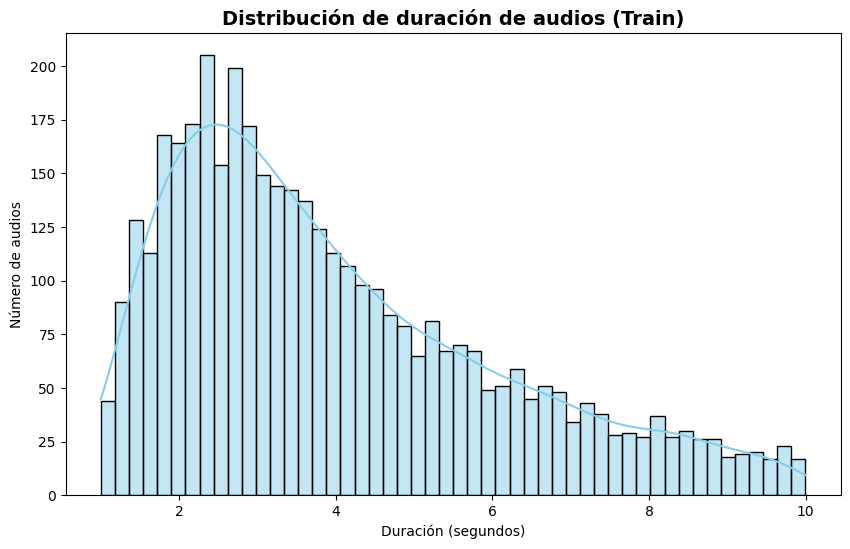

In [5]:
plt.figure(figsize=(10,6))
sns.histplot(durations, bins=50, kde=True, color='skyblue')
plt.title("Distribución de duración de audios (Train)", fontsize=14, fontweight='bold')
plt.xlabel("Duración (segundos)")
plt.ylabel("Número de audios")
plt.show()

In [6]:
# Calculamos pesos para compensar el desbalanceo (Menos samples = más peso)
print("\nCalculando pesos para clases desbalanceadas...")

labels_array = np.array(train_dataset['label'])
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(labels_array),
    y=labels_array
)

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("\nPesos calculados para CrossEntropyLoss:")
for i, (nombre, peso) in enumerate(zip(nombres_clases, class_weights)):
    print(f"  {nombres_clases[i]:10s}: peso = {peso:.3f}")


Calculando pesos para clases desbalanceadas...

Pesos calculados para CrossEntropyLoss:
  Neutral   : peso = 0.787
  Feliz     : peso = 0.890
  Triste    : peso = 1.138
  Enojado   : peso = 1.376


In [7]:
# Funciones de augmentación de audio
print("\nConfigurando data augmentation...")

def augment_audio(audio_array, sr=16000):
    """
    Aplica augmentación aleatoria al audio para aumentar la diversidad del dataset.
    Solo se aplica durante el entrenamiento, no en validación.
    """
    augmented = audio_array.copy()

    # 1. Añadir ruido gaussiano (probabilidad: 50%)
    if np.random.random() > 0.5:
        noise_level = np.random.uniform(0.001, 0.01)
        noise = np.random.randn(len(augmented)) * noise_level
        augmented = augmented + noise
        # Clip para evitar valores fuera de rango
        augmented = np.clip(augmented, -1, 1)

    # 2. Cambiar volumen (probabilidad: 30%)
    if np.random.random() > 0.7:
        gain = np.random.uniform(0.8, 1.2)
        augmented = augmented * gain
        augmented = np.clip(augmented, -1, 1)

    return augmented

print("Funciones de augmentación configuradas:")
print("  - Ruido gaussiano (50% prob)")
print("  - Cambio de volumen 80%-120% (30% prob)")


Configurando data augmentation...
Funciones de augmentación configuradas:
  - Ruido gaussiano (50% prob)
  - Cambio de volumen 80%-120% (30% prob)


In [8]:
# Cargamos el feature extractor
print("\nCargando Wav2Vec2 Feature Extractor...")
model_id = "facebook/wav2vec2-base"
feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(model_id)

def preprocess_function(examples, is_training=True):
    """
    Preprocesa los audios:
    - Aplica augmentación (solo en train)
    - Extrae características con Wav2Vec2
    """
    # Extraemos arrays de audio
    audio_arrays = [x["array"] for x in examples["audio"]]

    if is_training:
        audio_arrays = [augment_audio(audio, sr=16000) for audio in audio_arrays]

    inputs = feature_extractor(
        audio_arrays,
        sampling_rate=16000,
        padding="max_length",
        max_length=160000,
        truncation=True,
    )

    return {
        "input_values": inputs.input_values,
        "labels": examples["label"]
    }

print("Función de preprocesamiento configurada")
print("  - Augmentación: Activada en train, desactivada en eval")
print("  - Sampling rate: 16kHz")


Cargando Wav2Vec2 Feature Extractor...


preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

Función de preprocesamiento configurada
  - Augmentación: Activada en train, desactivada en eval
  - Sampling rate: 16kHz


In [9]:
# Aplicamos el preprocesamiento
print("\nPreprocesando dataset de ENTRENAMIENTO...")
encoded_train = train_dataset.map(
    lambda x: preprocess_function(x, is_training=True),
    batched=True,
    batch_size=16,
    remove_columns=train_dataset.column_names,
    load_from_cache_file=False,
    desc="Procesando train"
)

print("\nPreprocesando dataset de EVALUACIÓN...")
encoded_eval = eval_dataset.map(
    lambda x: preprocess_function(x, is_training=False),  # Sin augmentación
    batched=True,
    batch_size=16,
    remove_columns=eval_dataset.column_names,
    desc="Procesando eval"
)

# Configuramos formato para PyTorch
encoded_train = encoded_train.with_format("torch")
encoded_eval = encoded_eval.with_format("torch")

print("\nPreprocesamiento completado")
print(f"  Train samples: {len(encoded_train)}")
print(f"  Eval samples: {len(encoded_eval)}")


Preprocesando dataset de ENTRENAMIENTO...


Procesando train:   0%|          | 0/3995 [00:00<?, ? examples/s]


Preprocesando dataset de EVALUACIÓN...


Procesando eval:   0%|          | 0/1140 [00:00<?, ? examples/s]


Preprocesamiento completado
  Train samples: 3995
  Eval samples: 1140


In [10]:
# Cargamos el modelo
print("\nCargando modelo Wav2Vec2 para clasificación...")
model = Wav2Vec2ForSequenceClassification.from_pretrained(
    model_id,
    num_labels=4,
)
model.to(device)

# Congelamos el feature extractor (primeras capas CNN)
model.freeze_feature_encoder()
print("Feature extractor congelado (combate overfitting)")

# Creamos un Trainer personalizado que use los class weights
class WeightedTrainer(Trainer):
    """
    Trainer personalizado que aplica pesos a las clases desbalanceadas
    en la función de pérdida CrossEntropy.
    """
    def __init__(self, class_weights, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")

        loss_fct = torch.nn.CrossEntropyLoss(weight=self.class_weights)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))

        return (loss, outputs) if return_outputs else loss

print("WeightedTrainer configurado con class weights")


Cargando modelo Wav2Vec2 para clasificación...


config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  380MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  380MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] Wav2Vec2ForSequenceClassification LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     | 
-----------------------------+------------+-
project_q.weight             | UNEXPECTED | 
quantizer.codevectors        | UNEXPECTED | 
project_hid.bias             | UNEXPECTED | 
quantizer.weight_proj.bias   | UNEXPECTED | 
quantizer.weight_proj.weight | UNEXPECTED | 
project_q.bias               | UNEXPECTED | 
project_hid.weight           | UNEXPECTED | 
projector.bias               | MISSING    | 
classifier.weight            | MISSING    | 
classifier.bias              | MISSING    | 
projector.weight             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Feature extractor congelado (combate overfitting)
WeightedTrainer configurado con class weights


In [11]:
accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")
precision_metric = evaluate.load("precision")
recall_metric = evaluate.load("recall")

def compute_metrics(eval_pred):
    """
    Calcula múltiples métricas para evaluar el modelo de forma completa.
    """
    predictions, labels = eval_pred

    # Obtenemos la clase predicha (argmax de las probabilidades)
    predictions = np.argmax(predictions, axis=1)

    # Calculamos métricas
    accuracy = accuracy_metric.compute(predictions=predictions, references=labels)

    # F1-score macro: promedio simple (trata todas las clases igual)
    f1_macro = f1_metric.compute(
        predictions=predictions,
        references=labels,
        average="macro"
    )

    # F1-score weighted: promedio ponderado por soporte (considera desbalanceo)
    f1_weighted = f1_metric.compute(
        predictions=predictions,
        references=labels,
        average="weighted"
    )

    # Precisión y recall macro
    precision_macro = precision_metric.compute(
        predictions=predictions,
        references=labels,
        average="macro"
    )

    recall_macro = recall_metric.compute(
        predictions=predictions,
        references=labels,
        average="macro"
    )

    return {
        "accuracy": accuracy["accuracy"],
        "f1_macro": f1_macro["f1"],
        "f1_weighted": f1_weighted["f1"],
        "precision_macro": precision_macro["precision"],
        "recall_macro": recall_macro["recall"],
    }

print("Metricas configuradas:")
print("  - Accuracy: Precision general")
print("  - F1 Macro: Promedio simple (importante para clases minoritarias)")
print("  - F1 Weighted: Promedio ponderado por frecuencia")
print("  - Precision Macro: Precision promedio por clase")
print("  - Recall Macro: Recall promedio por clase")

Metricas configuradas:
  - Accuracy: Precision general
  - F1 Macro: Promedio simple (importante para clases minoritarias)
  - F1 Weighted: Promedio ponderado por frecuencia
  - Precision Macro: Precision promedio por clase
  - Recall Macro: Recall promedio por clase


In [12]:
# Configuramos los hiperparámetros de entrenamiento
print("\nConfigurando hiperparámetros de entrenamiento...")

training_args = TrainingArguments(
    output_dir="./wav2vec2-emociones-mejorado",

    seed=SEED,
    data_seed=SEED,
    
    # Estrategia de evaluación y guardado
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",

    # Hiperparámetros de optimización
    learning_rate=3e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,   # Batch efectivo = 8 × 2 = 16

    lr_scheduler_type="reduce_lr_on_plateau",
    lr_scheduler_kwargs={
        "mode": "max",          # "max" porque greater_is_better=True (F1 macro)
        "factor": 0.5,          # Multiplica el LR por 0.5 cuando se active
        "patience": 3,          # Épocas sin mejora antes de reducir
        "threshold": 1e-4,      # Mejora mínima para considerarla significativa
        "min_lr": 1e-7,         # LR mínimo al que puede llegar
        "eps": 1e-8,                # Evita división por cero
    "cooldown": 0,              # No esperar después de reducir
    },

    # Duración del entrenamiento
    num_train_epochs=30,
    warmup_steps=0.1,

    # Optimización de memoria y velocidad
    fp16=True,
    dataloader_num_workers=2,

    # Regularización
    weight_decay=0.02,
    max_grad_norm=1.0,

    # Guardado del mejor modelo
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=3,

    # Logging
    report_to="none",
    logging_steps=10,
)

print("TrainingArguments configurados:")
print(f"  - Batch size efectivo: {training_args.per_device_train_batch_size * training_args.gradient_accumulation_steps}")
print(f"  - Learning rate: {training_args.learning_rate}")
print(f"  - Épocas: {training_args.num_train_epochs}")
print(f"  - Métrica óptima: F1-Macro")
print(f"  - Warmup: {training_args.warmup_steps * 100}%")


Configurando hiperparámetros de entrenamiento...
TrainingArguments configurados:
  - Batch size efectivo: 16
  - Learning rate: 3e-05
  - Épocas: 30
  - Métrica óptima: F1-Macro
  - Warmup: 10.0%


In [13]:
print("\nInicializando Trainer...")

trainer = WeightedTrainer(
    class_weights=class_weights_tensor,
    model=model,
    args=training_args,
    train_dataset=encoded_train,
    eval_dataset=encoded_eval,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=5)
    ],
)

print("Trainer inicializado")
print(f"  - Samples de train: {len(encoded_train)}")
print(f"  - Samples de eval: {len(encoded_eval)}")
print(f"  - Early stopping: Paciencia de 5 épocas")
print(f"  - Class weights: Activados")


Inicializando Trainer...
Trainer inicializado
  - Samples de train: 3995
  - Samples de eval: 1140
  - Early stopping: Paciencia de 5 épocas
  - Class weights: Activados


In [14]:
# Iniciamos el entrenamiento
print("\n" + "="*60)
print("INICIANDO ENTRENAMIENTO")
print("="*60)
print(f"\nConfiguración:")
print(f"  - Modelo: Wav2Vec2-Base")
print(f"  - Dataset train: {len(encoded_train)} samples")
print(f"  - Dataset eval: {len(encoded_eval)} samples")
print(f"  - Batch size efectivo: 16")
print(f"  - Épocas maximas: 30")
print(f"  - Device: {device}")
print("\nEl entrenamiento se detendrá automáticamente si no mejora")
print("el F1-macro durante 5 épocas consecutivas (early stopping)")
print("\n" + "="*60)

# Entrenamos
train_result = trainer.train()

# Guardamos el mejor modelo
trainer.save_model("./wav2vec2-emociones-mejorado/best_model")
feature_extractor.save_pretrained("./wav2vec2-emociones-mejorado/best_model")

print("\nEntrenamiento completado")
print(f"Mejor modelo guardado en: ./wav2vec2-emociones-mejorado/best_model")


INICIANDO ENTRENAMIENTO

Configuración:
  - Modelo: Wav2Vec2-Base
  - Dataset train: 3995 samples
  - Dataset eval: 1140 samples
  - Batch size efectivo: 16
  - Épocas maximas: 30
  - Device: cuda

El entrenamiento se detendrá automáticamente si no mejora
el F1-macro durante 5 épocas consecutivas (early stopping)



/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted,Precision Macro,Recall Macro
1,2.338349,1.108052,0.471930,0.484239,0.462399,0.498499,0.549058
2,1.939747,0.973776,0.581579,0.593342,0.574353,0.599064,0.614918
3,1.632547,1.007579,0.557895,0.553570,0.538206,0.610542,0.612937
4,1.370371,0.874698,0.635965,0.650428,0.637540,0.667493,0.648353
5,1.148127,0.905914,0.657895,0.666928,0.656383,0.660235,0.686449
6,0.974130,0.961206,0.651754,0.658055,0.650295,0.665326,0.660025
7,0.801021,1.193677,0.615789,0.610263,0.609411,0.635542,0.634010
8,0.658220,1.063806,0.671930,0.673818,0.670640,0.668680,0.690612
9,0.587728,1.080827,0.666667,0.670375,0.662153,0.688082,0.678710
10,0.494054,1.254644,0.669298,0.672117,0.667919,0.683544,0.668214


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Entrenamiento completado
Mejor modelo guardado en: ./wav2vec2-emociones-mejorado/best_model



Generando curvas de entrenamiento...
Grafico guardado: training_curves.png


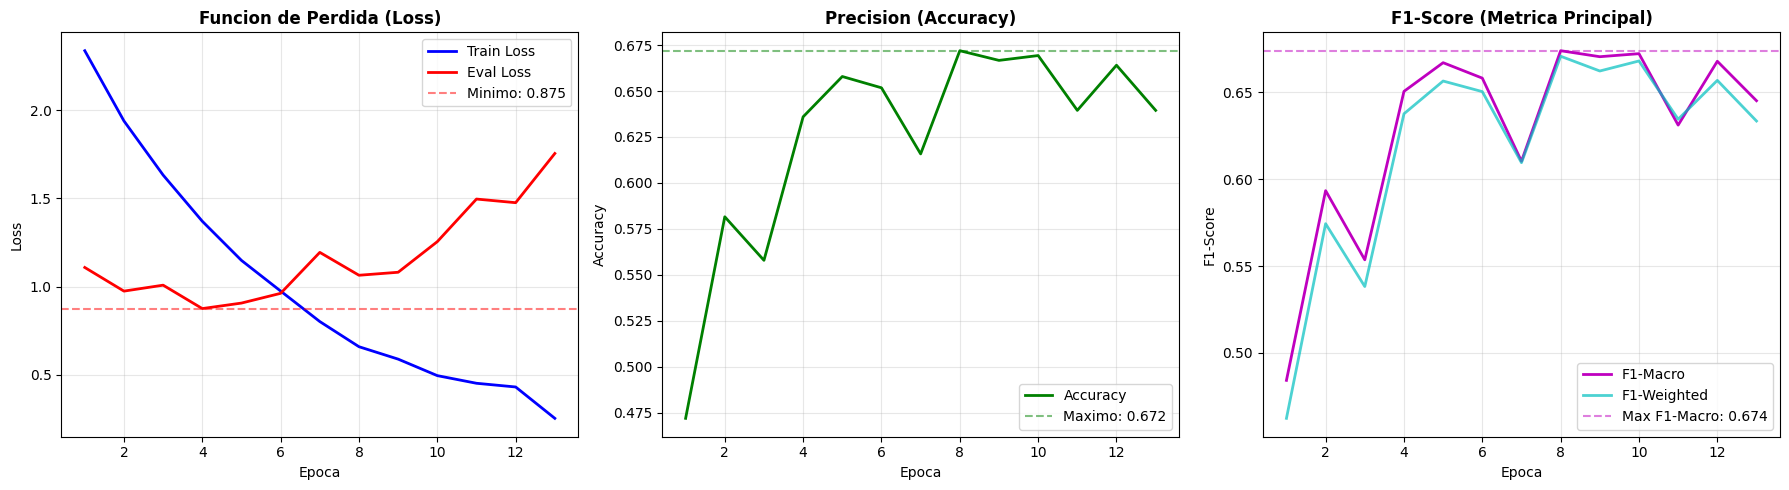


ESTADISTICAS FINALES DE ENTRENAMIENTO

MEJORES RESULTADOS:
  - Mejor época: 4
  - Mejor eval_loss: 0.8747
  - Mejor accuracy: 0.6719
  - Mejor F1-macro: 0.6738
  - Mejor F1-weighted: 0.6706

ÚLTIMA ÉPOCA:
  - Eval loss: 1.7551
  - Accuracy: 0.6395
  - F1-macro: 0.6451
  - F1-weighted: 0.6334

GAP DE OVERFITTING:
  - Train loss final: 0.2517
  - Eval loss final: 1.7551
  - Diferencia: 1.5034
  ALERTA: Posible overfitting (gap > 0.2)


In [15]:
print("\nGenerando curvas de entrenamiento...")

historial = trainer.state.log_history

# Filtramos las métricas
train_loss = [x['loss'] for x in historial if 'loss' in x and 'eval_loss' not in x]
eval_loss = [x['eval_loss'] for x in historial if 'eval_loss' in x]
eval_acc = [x['eval_accuracy'] for x in historial if 'eval_accuracy' in x]
eval_f1_macro = [x['eval_f1_macro'] for x in historial if 'eval_f1_macro' in x]
eval_f1_weighted = [x['eval_f1_weighted'] for x in historial if 'eval_f1_weighted' in x]

epocas = range(1, len(eval_loss) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Loss
axes[0].plot(epocas, train_loss, 'b-', linewidth=2, label='Train Loss')
axes[0].plot(epocas, eval_loss, 'r-', linewidth=2, label='Eval Loss')
axes[0].set_title('Funcion de Perdida (Loss)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoca')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].axhline(y=min(eval_loss), color='r', linestyle='--', alpha=0.5, label=f'Minimo: {min(eval_loss):.3f}')
axes[0].legend()

# Gráfico 2: Accuracy
axes[1].plot(epocas, eval_acc, 'g-', linewidth=2, label='Accuracy')
axes[1].set_title('Precision (Accuracy)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoca')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].axhline(y=max(eval_acc), color='g', linestyle='--', alpha=0.5, label=f'Maximo: {max(eval_acc):.3f}')
axes[1].legend()

# Gráfico 3: F1-Macro
axes[2].plot(epocas, eval_f1_macro, 'm-', linewidth=2, label='F1-Macro')
axes[2].plot(epocas, eval_f1_weighted, 'c-', linewidth=2, label='F1-Weighted', alpha=0.7)
axes[2].set_title('F1-Score (Metrica Principal)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Epoca')
axes[2].set_ylabel('F1-Score')
axes[2].legend()
axes[2].grid(True, alpha=0.3)
axes[2].axhline(y=max(eval_f1_macro), color='m', linestyle='--', alpha=0.5, label=f'Max F1-Macro: {max(eval_f1_macro):.3f}')
axes[2].legend()

plt.tight_layout()
plt.savefig('./wav2vec2-emociones-mejorado/training_curves.png', dpi=300, bbox_inches='tight')
print("Grafico guardado: training_curves.png")
plt.show()

# Estadísticas finales
print("\n" + "="*60)
print("ESTADISTICAS FINALES DE ENTRENAMIENTO")
print("="*60)
print(f"\nMEJORES RESULTADOS:")
print(f"  - Mejor época: {np.argmin(eval_loss) + 1}")
print(f"  - Mejor eval_loss: {min(eval_loss):.4f}")
print(f"  - Mejor accuracy: {max(eval_acc):.4f}")
print(f"  - Mejor F1-macro: {max(eval_f1_macro):.4f}")
print(f"  - Mejor F1-weighted: {max(eval_f1_weighted):.4f}")

print(f"\nÚLTIMA ÉPOCA:")
print(f"  - Eval loss: {eval_loss[-1]:.4f}")
print(f"  - Accuracy: {eval_acc[-1]:.4f}")
print(f"  - F1-macro: {eval_f1_macro[-1]:.4f}")
print(f"  - F1-weighted: {eval_f1_weighted[-1]:.4f}")

print(f"\nGAP DE OVERFITTING:")
print(f"  - Train loss final: {train_loss[-1]:.4f}")
print(f"  - Eval loss final: {eval_loss[-1]:.4f}")
print(f"  - Diferencia: {abs(train_loss[-1] - eval_loss[-1]):.4f}")
if abs(train_loss[-1] - eval_loss[-1]) > 0.2:
    print("  ALERTA: Posible overfitting (gap > 0.2)")
else:
    print("  Gap aceptable")


Realizando evaluación final en el set de validación...


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



REPORTE DE CLASIFICACIÓN DETALLADO
              precision    recall  f1-score   support

     Neutral     0.6482    0.7049    0.6754       366
       Feliz     0.7327    0.6040    0.6621       404
      Triste     0.6168    0.8250    0.7059       160
     Enojado     0.6769    0.6286    0.6519       210

    accuracy                         0.6719      1140
   macro avg     0.6687    0.6906    0.6738      1140
weighted avg     0.6791    0.6719    0.6706      1140


Generando matriz de confusión...
Matriz de confusion guardada: confusion_matrix.png


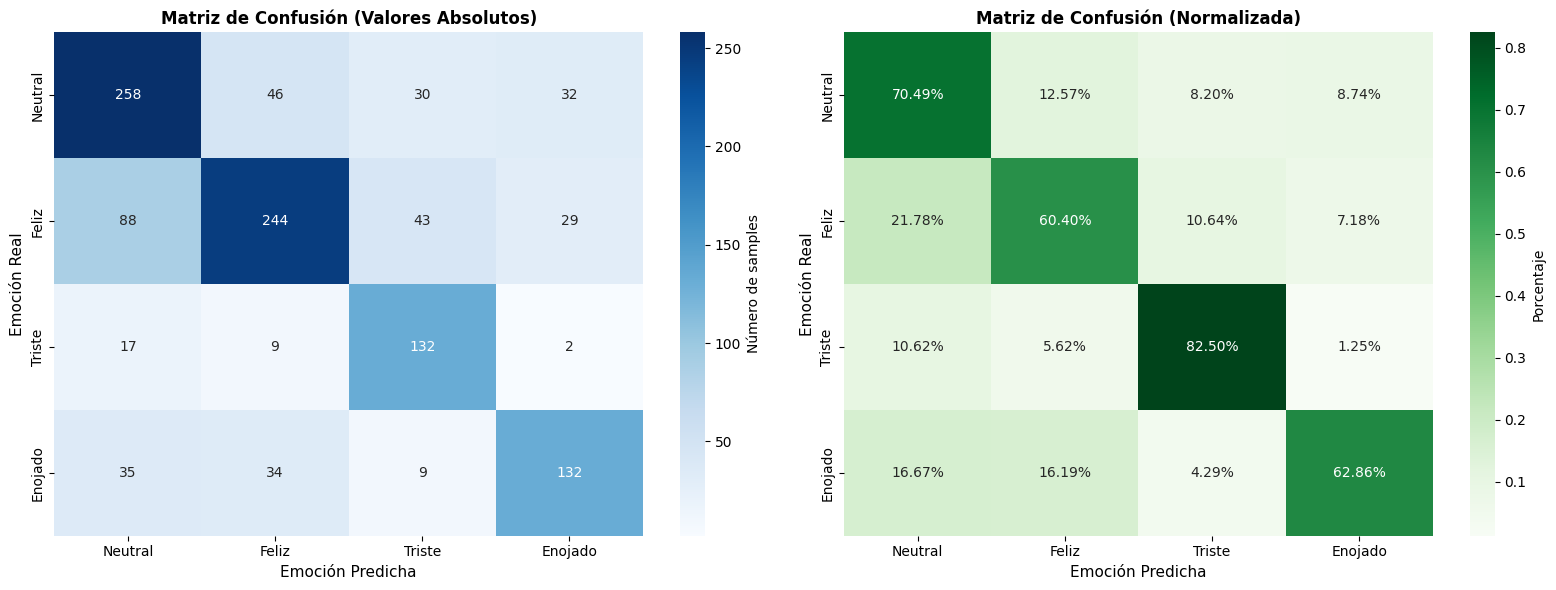


ANÁLISIS DETALLADO POR CLASE

NEUTRAL:
  - Samples reales: 366
  - Samples predichos: 398
  - Correctamente clasificados: 258 (70.5%)
  - Precision: 0.6482
  - Recall: 0.7049
  - F1-Score: 0.6754

FELIZ:
  - Samples reales: 404
  - Samples predichos: 333
  - Correctamente clasificados: 244 (60.4%)
  - Precision: 0.7327
  - Recall: 0.6040
  - F1-Score: 0.6621

TRISTE:
  - Samples reales: 160
  - Samples predichos: 214
  - Correctamente clasificados: 132 (82.5%)
  - Precision: 0.6168
  - Recall: 0.8250
  - F1-Score: 0.7059

ENOJADO:
  - Samples reales: 210
  - Samples predichos: 195
  - Correctamente clasificados: 132 (62.9%)
  - Precision: 0.6769
  - Recall: 0.6286
  - F1-Score: 0.6519

MÉTRICAS GLOBALES
  - Accuracy: 0.6719 (67.19%)
  - F1-Macro: 0.6738
  - F1-Weighted: 0.6706
  - Precision-Macro: 0.6687
  - Recall-Macro: 0.6906

COMPARACIÓN CON BASELINE:
  - Accuracy aleatoria: 0.2500 (25.00%)
  - Mejora sobre baseline: 0.4219 (42.19%)
  - Factor de mejora: 2.69x

EVALUACIÓN COMPLETA

In [16]:
# Realizamos predicciones finales
print("\nRealizando evaluación final en el set de validación...")

predictions = trainer.predict(encoded_eval)

# Obtenemos labels reales y predichos
y_true = predictions.label_ids
y_pred = np.argmax(predictions.predictions, axis=1)

# 1. REPORTE DE CLASIFICACIÓN DETALLADO
print("\n" + "="*60)
print("REPORTE DE CLASIFICACIÓN DETALLADO")
print("="*60)
print(classification_report(y_true, y_pred, target_names=nombres_clases, digits=4))

# 2. MATRIZ DE CONFUSIÓN
print("\nGenerando matriz de confusión...")

cm = confusion_matrix(y_true, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Matriz absoluta
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=nombres_clases, yticklabels=nombres_clases,
            ax=axes[0], cbar_kws={'label': 'Número de samples'})
axes[0].set_title('Matriz de Confusión (Valores Absolutos)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Emoción Real', fontsize=11)
axes[0].set_xlabel('Emoción Predicha', fontsize=11)

# Matriz normalizada
sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap='Greens',
            xticklabels=nombres_clases, yticklabels=nombres_clases,
            ax=axes[1], cbar_kws={'label': 'Porcentaje'})
axes[1].set_title('Matriz de Confusión (Normalizada)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Emoción Real', fontsize=11)
axes[1].set_xlabel('Emoción Predicha', fontsize=11)

plt.tight_layout()
plt.savefig('./wav2vec2-emociones-mejorado/confusion_matrix.png', dpi=300, bbox_inches='tight')
print("Matriz de confusion guardada: confusion_matrix.png")
plt.show()

# 3. ANÁLISIS DETALLADO POR CLASE
print("\n" + "="*60)
print("ANÁLISIS DETALLADO POR CLASE")
print("="*60)

from sklearn.metrics import precision_score, recall_score, f1_score

precisions = precision_score(y_true, y_pred, average=None)
recalls = recall_score(y_true, y_pred, average=None)
f1s = f1_score(y_true, y_pred, average=None)

for i, clase in enumerate(nombres_clases):
    precision = precisions[i]
    recall = recalls[i]
    f1 = f1s[i]

    total_real = np.sum(np.array(y_true) == i)
    total_pred = np.sum(np.array(y_pred) == i)
    correct = np.sum((np.array(y_true) == i) & (np.array(y_pred) == i))

    print(f"\n{clase.upper()}:")
    print(f"  - Samples reales: {total_real}")
    print(f"  - Samples predichos: {total_pred}")
    print(f"  - Correctamente clasificados: {correct} ({correct/total_real*100:.1f}%)")
    print(f"  - Precision: {precision:.4f}")
    print(f"  - Recall: {recall:.4f}")
    print(f"  - F1-Score: {f1:.4f}")


# 4. MÉTRICAS GLOBALES
print("\n" + "="*60)
print("MÉTRICAS GLOBALES")
print("="*60)

accuracy = np.mean(np.array(y_true) == np.array(y_pred))
f1_macro = f1_score(y_true, y_pred, average='macro')
f1_weighted = f1_score(y_true, y_pred, average='weighted')
precision_macro = precision_score(y_true, y_pred, average='macro')
recall_macro = recall_score(y_true, y_pred, average='macro')

print(f"  - Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"  - F1-Macro: {f1_macro:.4f}")
print(f"  - F1-Weighted: {f1_weighted:.4f}")
print(f"  - Precision-Macro: {precision_macro:.4f}")
print(f"  - Recall-Macro: {recall_macro:.4f}")

print(f"\nCOMPARACIÓN CON BASELINE:")
print(f"  - Accuracy aleatoria: {1/len(nombres_clases):.4f} ({1/len(nombres_clases)*100:.2f}%)")
print(f"  - Mejora sobre baseline: {accuracy - 1/len(nombres_clases):.4f} ({(accuracy - 1/len(nombres_clases))*100:.2f}%)")
print(f"  - Factor de mejora: {accuracy / (1/len(nombres_clases)):.2f}x")

print("\n" + "="*60)
print("EVALUACIÓN COMPLETADA")
print("="*60)